# Interpolación entre imágenes vía transporte óptimo dinámico

***
Morphing entre dos imágenes como **transporte óptimo dinámico de Benamou–Brenier** (control óptimo): estado = densidad $\rho$, control = momento $m=\rho v$, restricción = continuidad $\partial_t\rho+\nabla\!\cdot m=0$, y se minimiza la energía cinética $\int\!\!\int \Phi(\rho,m)$ con $\Phi(\rho,m)=\dfrac{|m|^2}{2\rho}$.

**Método:** splitting proximal en forma **Douglas–Rachford de promedio paralelo (PPXA)** sobre tres prox: energía (cúbica, Prop. 3.1), continuidad (Poisson–Neumann vía DCT, §3.3) y consenso escalonada↔centrada (§3.4). Validación de abajo hacia arriba: cada pieza con su test antes de ensamblar.

## Preliminares y convenciones

- **Grilla escalonada 3D** $(x,y,t)$, `dim=(N,P,Q)`. `M[1],M[2]`=momento, `M[3]`=densidad
  $\rho$ (eje temporal); cada `M[k]` tiene su eje $k$ con un punto más.
- **Factor $\tfrac12$:** uso mi convención $\Phi=\dfrac{|m|^2}{2\rho}$; la cúbica se deriva de
  la Prop. 3.1, no se copian coeficientes del `proxJ` del repositorio.
- **Datos $\rho_0,\rho_1$:** por inicialización + invariancia de caras (Poisson Neumann en
  los tres ejes, nadie toca las caras extremas).

Paquetes (una vez): `] add FFTW` (y `Plots` para visualizar).

In [1]:
using FFTW
using LinearAlgebra
using Printf
using Random
using Plots      # descomentar para visualizar
Random.seed!(0)
println("Entorno cargado.")

Entorno cargado.


In [2]:
# Campo escalonado: M[1],M[2]=momento, M[3]=densidad rho (eje temporal).
struct Staggered
    dim
    M
end

function Staggered(dim)
    N, P, Q = dim
    M1 = zeros(N+1, P,   Q  )
    M2 = zeros(N,   P+1, Q  )
    M3 = zeros(N,   P,   Q+1)
    return Staggered(dim, [M1, M2, M3])
end

import Base: +, -, *
function +(A::Staggered, B::Staggered)
    C = Staggered(A.dim)
    for k in 1:3; C.M[k] = A.M[k] + B.M[k]; end
    return C
end
function -(A::Staggered, B::Staggered)
    C = Staggered(A.dim)
    for k in 1:3; C.M[k] = A.M[k] - B.M[k]; end
    return C
end
function *(a::Real, A::Staggered)
    C = Staggered(A.dim)
    for k in 1:3; C.M[k] = a * A.M[k]; end
    return C
end

copia(A::Staggered) = Staggered(A.dim, [copy(A.M[k]) for k in 1:3])

function dotp_stag(X, Y)
    s = 0.0
    for k in 1:3; s = s + sum(X.M[k] .* Y.M[k]); end
    return s
end

function random_staggered(dim)
    U = Staggered(dim)
    for k in 1:3; U.M[k] = randn(size(U.M[k])); end
    return U
end

println("Struct Staggered y operaciones listas.")

Struct Staggered y operaciones listas.


## §1 — Variables del sistema y convexificación

Cambio de variable $m=\rho v$: energía = función perspectiva $\Phi=\dfrac{|m|^2}{2\rho}$
(convexa, s.c.i.), restricción lineal. La energía se evalúa sobre la grilla centrada
$V=\mathcal I(U)$ de tamaño $(N,P,Q,3)$.

In [3]:
# Energia cinetica discreta: suma de |m|^2 / (2 rho^beta)  (convencion con 1/2).
function energia_BB(V; ε=1e-10, β=1.0)
    m2  = V[:,:,:,1].^2 .+ V[:,:,:,2].^2
    ρ   = max.(V[:,:,:,3], ε)
    return sum(m2 ./ (2 .* ρ.^β))
end
println("energia_BB lista.")

energia_BB lista.


## §2 — Condiciones de optimalidad (sistema estado-adjunto)

$v=\nabla\varphi$ y $\partial_t\varphi+\tfrac12|\nabla\varphi|^2=0$, acopladas con la
continuidad. El adjunto $\varphi$ es el multiplicador de la restricción de continuidad
(§3.5); se asocia a la pieza `div_proj`.

## §3 — Método numérico

$\min_U\; J(\mathcal I(U)) + \iota_{\mathrm{div}}(U)$ con consenso $V=\mathcal I(U)$,
resuelto por PPXA sobre tres prox simples.

### Fase 1 — Operadores de grilla (divergencia, interpolación, adjunto)

In [4]:
# interp: escalonada -> centrada (promedio de caras vecinas /2). Devuelve (N,P,Q,3).
function interp(U)
    N, P, Q = U.dim
    V = zeros(N, P, Q, 3)
    V[:,:,:,1] = (U.M[1][1:end-1,:,:] .+ U.M[1][2:end,:,:]) ./ 2
    V[:,:,:,2] = (U.M[2][:,1:end-1,:] .+ U.M[2][:,2:end,:]) ./ 2
    V[:,:,:,3] = (U.M[3][:,:,1:end-1] .+ U.M[3][:,:,2:end]) ./ 2
    return V
end

# interp_adj: adjunto de interp. Cumple <U, interp_adj(V)> = <interp(U), V>.
function interp_adj(V)
    N, P, Q = size(V,1), size(V,2), size(V,3)
    U = Staggered((N,P,Q))
    U.M[1][1,:,:]   = V[1,:,:,1]
    U.M[1][2:N,:,:] = V[1:N-1,:,:,1] .+ V[2:N,:,:,1]
    U.M[1][N+1,:,:] = V[N,:,:,1]
    U.M[1] ./= 2
    U.M[2][:,1,:]   = V[:,1,:,2]
    U.M[2][:,2:P,:] = V[:,1:P-1,:,2] .+ V[:,2:P,:,2]
    U.M[2][:,P+1,:] = V[:,P,:,2]
    U.M[2] ./= 2
    U.M[3][:,:,1]   = V[:,:,1,3]
    U.M[3][:,:,2:Q] = V[:,:,1:Q-1,3] .+ V[:,:,2:Q,3]
    U.M[3][:,:,Q+1] = V[:,:,Q,3]
    U.M[3] ./= 2
    return U
end

# div: divergencia espacio-temporal  d_t rho + div m.
function div_stag(U; lx=1.0, ly=1.0, lt=1.0)
    N, P, Q = U.dim
    v  = diff(U.M[1], dims=1) .* (N/lx)
    v  = v .+ diff(U.M[2], dims=2) .* (P/ly)
    v  = v .+ diff(U.M[3], dims=3) .* (Q/lt)
    return v
end

println("Fase 1 lista.")

Fase 1 lista.


In [5]:
# TEST Fase 1: adjunto de interp. Debe dar ~1e-15.
d = (12, 10, 8)
U = random_staggered(d)
V = randn(d[1], d[2], d[3], 3)
lado_izq = sum(interp(U) .* V)
lado_der = dotp_stag(U, interp_adj(V))
@printf("Test adjunto interp:  error relativo = %.3e\n",
        abs(lado_izq - lado_der) / abs(lado_izq))

Test adjunto interp:  error relativo = 5.334e-16


### Fase 2a — Operador proximal de la energía: la cúbica (§3.2)

Para $\beta=1$ (Prop. 3.1, con $\tfrac12$): $\rho^\*$ = raíz positiva de
$P(\rho)=(\rho-\tilde\rho)(\rho+\gamma)^2-\tfrac{\gamma}{2}|\tilde m|^2$, luego
$m=\frac{\rho}{\rho+\gamma}\tilde m$. Se resuelve por Newton desde un punto a la derecha de
la raíz (región convexa creciente). Para $\beta\in[0,1)$, polinomio $P_\beta$ (Prop. 5.4).

In [6]:
# prox_energia: prox de la energia, punto a punto. Convencion con 1/2.
function prox_energia(V, γ; ε=1e-8, β=1.0)
    mx = V[:,:,:,1]
    my = V[:,:,:,2]
    ρ0 = V[:,:,:,3]
    m02 = mx.^2 .+ my.^2
    if β == 0.0
        ρ = max.(ρ0, ε)
    elseif β == 1.0
        # Newton sobre P(ρ)=(ρ-ρ0)(ρ+γ)^2-(γ/2)m02, inicial a la derecha de la raiz
        ρ = ρ0 .+ m02 ./ (2γ) .+ ε
        for _ in 1:60
            Pr  = (ρ .- ρ0) .* (ρ .+ γ).^2 .- (γ/2) .* m02
            dPr = (ρ .+ γ) .* (3 .* ρ .+ γ .- 2 .* ρ0)
            ρ   = ρ .- Pr ./ dPr
            ρ   = max.(ρ, ε)
        end
    else
        # Newton sobre P_beta (derivada numerica)
        ρ = max.(ρ0, ε)
        for _ in 1:80
            rb  = ρ .^ β
            Pr  = ρ.^(1-β) .* (ρ .- ρ0) .* (rb .+ γ).^2 .- (γ*β/2) .* m02
            h   = 1e-7 .* max.(ρ, 1.0)
            ρ2  = ρ .+ h
            rb2 = ρ2 .^ β
            Pr2 = ρ2.^(1-β) .* (ρ2 .- ρ0) .* (rb2 .+ γ).^2 .- (γ*β/2) .* m02
            dPr = (Pr2 .- Pr) ./ h
            ρ   = ρ .- Pr ./ dPr
            ρ   = max.(ρ, ε)
        end
    end
    rb = ρ .^ β
    out = similar(V)
    out[:,:,:,1] = (rb ./ (rb .+ γ)) .* mx
    out[:,:,:,2] = (rb ./ (rb .+ γ)) .* my
    out[:,:,:,3] = ρ
    return out
end
println("prox_energia lista.")

prox_energia lista.


In [7]:
# TEST Fase 2a: P(ρ*) debe anularse (beta=1).
V0 = randn(6, 6, 6, 3)
V0[:,:,:,3] .= abs.(V0[:,:,:,3]) .+ 0.1
γ  = 0.3
V1 = prox_energia(V0, γ; β=1.0)
ρ   = V1[:,:,:,3]
ρ0  = V0[:,:,:,3]
m02 = V0[:,:,:,1].^2 .+ V0[:,:,:,2].^2
P   = (ρ .- ρ0) .* (ρ .+ γ).^2 .- (γ/2) .* m02
@printf("Test cubica:  max|P(rho*)| = %.3e\n", maximum(abs.(P)))

Test cubica:  max|P(rho*)| = 3.275e-15


### Fase 2b — Poisson–Neumann (DCT) y proyección sobre continuidad (§3.3)

$\operatorname{div}$-proj resuelve $p$ con $\Delta p=\operatorname{div}U$ y corrige
$v=U-\nabla p$ solo en caras interiores (preserva datos y no-flujo). El Poisson es Neumann
en los tres ejes.

In [8]:
# Poisson 2D Neumann por DCT. Resuelve -Lap(u)=f, devuelve u de media nula.
function poisson_neumann_2d(f; lx=1.0, ly=1.0)
    N, M = size(f)
    hx = lx/N; hy = ly/M
    λx = (2 .* cos.(π .* (0:N-1) ./ N) .- 2) ./ hx^2
    λy = (2 .* cos.(π .* (0:M-1) ./ M) .- 2) ./ hy^2
    denom = zeros(N, M)
    for i in 1:N, j in 1:M
        denom[i,j] = λx[i] + λy[j]
    end
    denom[1,1] = 1.0
    uhat = -dct(f) ./ denom
    uhat[1,1] = 0.0
    return idct(uhat)
end

# Poisson 3D Neumann (x,y,t). Mismo metodo.
function poisson_neumann_3d(f; lx=1.0, ly=1.0, lt=1.0)
    N, M, Q = size(f)
    hx = lx/N; hy = ly/M; ht = lt/Q
    λx = (2 .* cos.(π .* (0:N-1) ./ N) .- 2) ./ hx^2
    λy = (2 .* cos.(π .* (0:M-1) ./ M) .- 2) ./ hy^2
    λt = (2 .* cos.(π .* (0:Q-1) ./ Q) .- 2) ./ ht^2
    denom = zeros(N, M, Q)
    for i in 1:N, j in 1:M, k in 1:Q
        denom[i,j,k] = λx[i] + λy[j] + λt[k]
    end
    denom[1,1,1] = 1.0
    uhat = -dct(f) ./ denom
    uhat[1,1,1] = 0.0
    return idct(uhat)
end

println("Poisson 2D/3D listas.")

Poisson 2D/3D listas.


In [9]:
# TEST Poisson: autoconsistencia 2D + convergencia de orden 2.
function lap_neumann_2d(u; lx=1.0, ly=1.0)
    N, M = size(u); hx = lx/N; hy = ly/M
    λx = (2 .* cos.(π .* (0:N-1) ./ N) .- 2) ./ hx^2
    λy = (2 .* cos.(π .* (0:M-1) ./ M) .- 2) ./ hy^2
    denom = zeros(N, M)
    for i in 1:N, j in 1:M; denom[i,j] = λx[i] + λy[j]; end
    return idct(denom .* dct(u))
end

f = randn(32, 48); f = f .- sum(f)/length(f)
u = poisson_neumann_2d(f)
@printf("Poisson Test 1:  ||-Lap u - f||_inf = %.3e\n",
        maximum(abs.(-lap_neumann_2d(u) .- f)))

function error_mms(N; a=1, b=2)
    x = ((0:N-1) .+ 0.5) ./ N
    y = ((0:N-1) .+ 0.5) ./ N
    ue = [cos(a*π*xi)*cos(b*π*yj) for xi in x, yj in y]
    ue = ue .- sum(ue)/length(ue)
    f  = (a^2+b^2)*π^2 .* ue
    return maximum(abs.(poisson_neumann_2d(f) .- ue))
end
println("Poisson Test 2 (orden de convergencia):")
err_ant = 0.0
for N in (16, 32, 64, 128)
    err = error_mms(N)
    if err_ant == 0.0
        @printf("   N=%4d   error=%.3e\n", N, err)
    else
        @printf("   N=%4d   error=%.3e   factor=%.2f\n", N, err, err_ant/err)
    end
    global err_ant = err
end

Poisson Test 1:  ||-Lap u - f||_inf = 2.257e-14
Poisson Test 2 (orden de convergencia):
   N=  16   error=1.073e-02
   N=  32   error=2.719e-03   factor=3.95
   N=  64   error=6.819e-04   factor=3.99
   N= 128   error=1.706e-04   factor=4.00


In [10]:
# div_proj: proyeccion sobre {div U = 0}. Corrige solo caras interiores.
function div_proj(U; lx=1.0, ly=1.0, lt=1.0)
    N, P, Q = U.dim
    du = div_stag(U; lx=lx, ly=ly, lt=lt)
    p  = poisson_neumann_3d(-du; lx=lx, ly=ly, lt=lt)
    v  = copia(U)
    v.M[1][2:end-1,:,:] .-= diff(p, dims=1) .* (N/lx)
    v.M[2][:,2:end-1,:] .-= diff(p, dims=2) .* (P/ly)
    v.M[3][:,:,2:end-1] .-= diff(p, dims=3) .* (Q/lt)
    return v
end
println("div_proj lista.")

div_proj lista.


In [11]:
# TEST Fase 2b: div_proj sobre campo con bordes FISICOS (masa conservada).
# (Con un campo arbitrario FALLA: div(U) tendria media no nula, no proyectable.
#  Es la condicion de compatibilidad de la Prop. 1.1.)
d = (16, 16, 16)
U = random_staggered(d)
U.M[1][1,:,:] .= 0; U.M[1][end,:,:] .= 0      # no-flujo en x
U.M[2][:,1,:] .= 0; U.M[2][:,end,:] .= 0      # no-flujo en y
ga = rand(16,16); ga ./= sum(ga)
gb = rand(16,16); gb ./= sum(gb)
U.M[3][:,:,1] = ga; U.M[3][:,:,end] = gb      # datos de igual masa
Up = div_proj(U)
@printf("Test div_proj:  ||div(Up)||_inf = %.3e\n", maximum(abs.(div_stag(Up))))
println("Caras rho intactas: ", Up.M[3][:,:,1] == ga && Up.M[3][:,:,end] == gb)

Test div_proj:  ||div(Up)||_inf = 9.948e-14
Caras rho intactas: true


### Fase 2c — Proyección de consenso escalonada ↔ centrada (§3.4)

Proyecta $(U,V)$ sobre $\{V=\mathcal I(U)\}$ con datos en las caras. Se resuelve línea por
línea a lo largo de cada eje con una pequeña pseudoinversa del operador afín (una vez por
tamaño de eje).

In [12]:
# Matrices de proyeccion para una linea de longitud centrada n.
# Restriccion: v = S u (interpolacion), u(1)=a, u(end)=b.
function proj_ops(n)
    S = zeros(n, n+1)
    for i in 1:n
        S[i, i]   = 0.5
        S[i, i+1] = 0.5
    end
    A = zeros(n+2, 2n+1)
    A[1:n, 1:n+1]      = S
    A[1:n, n+2:2n+1]   = -Matrix(I, n, n)
    A[n+1, 1]          = 1.0      # u(1)=a
    A[n+2, n+1]        = 1.0      # u(end)=b
    pA = pinv(A)
    B  = Matrix(I, 2n+1, 2n+1) - pA * A
    return pA, B
end

# interp_proj: proyecta (U,V) sobre {V=interp(U)} con rho(.,0)=f0, rho(.,1)=f1.
function interp_proj(U, V, f0, f1)
    N, P, Q = U.dim
    U = copia(U); V = copy(V)
    # --- eje temporal (k=3): a=f0, b=f1 ---
    pA, B = proj_ops(Q)
    for i in 1:N, j in 1:P
        u0 = U.M[3][i,j,:]
        v0 = V[i,j,:,3]
        g = zeros(Q+2); g[Q+1] = f0[i,j]; g[Q+2] = f1[i,j]
        uv = B * vcat(u0, v0) + pA * g
        U.M[3][i,j,:] = uv[1:Q+1]
        V[i,j,:,3]    = uv[Q+2:end]
    end
    # --- eje x (k=1): no-flujo, a=b=0 ---
    pA, B = proj_ops(N)
    g = zeros(N+2)
    for j in 1:P, t in 1:Q
        u0 = U.M[1][:,j,t]
        v0 = V[:,j,t,1]
        uv = B * vcat(u0, v0) + pA * g
        U.M[1][:,j,t] = uv[1:N+1]
        V[:,j,t,1]    = uv[N+2:end]
    end
    # --- eje y (k=2): no-flujo, a=b=0 ---
    pA, B = proj_ops(P)
    g = zeros(P+2)
    for i in 1:N, t in 1:Q
        u0 = U.M[2][i,:,t]
        v0 = V[i,:,t,2]
        uv = B * vcat(u0, v0) + pA * g
        U.M[2][i,:,t] = uv[1:P+1]
        V[i,:,t,2]    = uv[P+2:end]
    end
    return U, V
end
println("interp_proj lista.")

interp_proj lista.


In [13]:
# TEST Fase 2c: V = interp(U) tras proyectar, y datos en las caras.
d = (16, 16, 16)
U = random_staggered(d); Vc = randn(d..., 3)
f0 = rand(16,16); f1 = rand(16,16)
Up, Vp = interp_proj(U, Vc, f0, f1)
@printf("Test interp_proj:  ||V - interp(U)||_inf = %.3e\n", maximum(abs.(Vp .- interp(Up))))
println("rho(.,0)=f0: ", isapprox(Up.M[3][:,:,1], f0), "   rho(.,end)=f1: ", isapprox(Up.M[3][:,:,end], f1))

Test interp_proj:  ||V - interp(U)||_inf = 5.967e-15
rho(.,0)=f0: true   rho(.,end)=f1: true


### §3.5 / Fase 3 — Bucle Douglas–Rachford (PPXA)

Tres prox por promedio paralelo ($\omega=[1,1,1]/3$). `prox_energia`↔funcional,
`div_proj`↔restricción de estado, la variable intermedia↔multiplicador $\varphi$.
Referencia: $\mu=1.98$, $\gamma=1/230$.

In [14]:
# solve_bb: resuelve el problema BB por PPXA. Devuelve Xu, V=interp(Xu) e historiales.
# Rendimiento: las actualizaciones PPXA se hacen IN-PLACE (@. sobre los arreglos, con buffers
# reutilizados) para no crear un Staggered nuevo por operación. El resultado es idéntico; evita
# asignar decenas de GiB y pasar el tiempo en recolección de basura. El registro se muestrea
# cada `log_every` iteraciones (hist.J no se usa en figuras, así que ese Poisson extra es barato).
function solve_bb(f0, f1, dim; β=1.0, ε=1e-6, μ=1.98, γ=1/230, niter=1000, verbose=0, log_every=10)
    N, P, Q = dim
    # inicializacion: blending lineal en M[3]
    Xu = Staggered(dim)
    ts = range(0, 1; length=Q+1)
    for i in 1:(Q+1)
        Xu.M[3][:,:,i] = (1-ts[i]) .* f0 .+ ts[i] .* f1
    end
    Xv = interp(Xu)
    ω = [1/3, 1/3, 1/3]
    Yu = [copia(Xu) for _ in 1:3]
    Yv = [copy(Xv) for _ in 1:3]
    Jhist = Float64[]; divhist = Float64[]; minhist = Float64[]
    Zu = Vector{Any}(undef, 3); Zv = Vector{Any}(undef, 3)
    Zu_s = Staggered(dim); Zv_s = zeros(N, P, Q, 3)   # buffers del promedio (reutilizados)
    for it in 1:niter
        # prox 1: energia (toca V) ; prox 2: continuidad (toca U) ; prox 3: consenso
        Zu[1] = Yu[1];              Zv[1] = prox_energia(Yv[1], γ/ω[1]; ε=ε, β=β)
        Zu[2] = div_proj(Yu[2]);    Zv[2] = Yv[2]
        Zu[3], Zv[3] = interp_proj(Yu[3], Yv[3], f0, f1)

        # promedio Z_s = sum_k omega_k Z_k  (acumulado in-place en los buffers)
        for c in 1:3; Zu_s.M[c] .= 0.0; end
        Zv_s .= 0.0
        for k in 1:3
            wk = ω[k]
            for c in 1:3
                zs = Zu_s.M[c]; zk = Zu[k].M[c]
                @. zs = zs + wk * zk
            end
            zvk = Zv[k]
            @. Zv_s = Zv_s + wk * zvk
        end

        # actualizaciones PPXA (in-place): Y_k += mu (2 Z_s - X - Z_k)
        for k in 1:3
            for c in 1:3
                yk = Yu[k].M[c]; zk = Zu[k].M[c]; zs = Zu_s.M[c]; xu = Xu.M[c]
                @. yk = yk + μ * (2*zs - xu - zk)
            end
            yv = Yv[k]; zv = Zv[k]
            @. yv = yv + μ * (2*Zv_s - Xv - zv)
        end

        # actualizacion de X (in-place): X += mu (Z_s - X)
        for c in 1:3
            xu = Xu.M[c]; zs = Zu_s.M[c]
            @. xu = xu + μ * (zs - xu)
        end
        @. Xv = Xv + μ * (Zv_s - Xv)

        # registro: solo cada log_every iteraciones (mas la primera y la ultima)
        if it == 1 || it == niter || it % log_every == 0
            Vc = interp(div_proj(Xu))
            push!(Jhist, energia_BB(Vc; ε=1e-3, β=β))
            push!(divhist, maximum(abs.(div_stag(Xu))))
            push!(minhist, minimum(interp(Xu)[:,:,:,3]))
            if verbose > 0
                @printf("    it=%4d/%d  ||div||=%.2e  minρ=%.2e\n", it, niter, divhist[end], minhist[end])
            end
        end
    end
    return Xu, interp(Xu), (J=Jhist, div=divhist, minρ=minhist)
end
println("solve_bb lista.")

solve_bb lista.


### §3.6 — Aceleración: `interp_proj` vectorizado

Mismo cálculo que `interp_proj` (misma `proj_ops`, misma proyección afín por línea), pero apilando
las líneas de cada eje como columnas y aplicando $B$, $p_A$ en un producto matricial por eje (BLAS).
No cambia los números, solo el costo. **Se activa aquí, antes de toda la validación, para que §4, §5
y §6 corran rápido.** Se prueba contra la versión original antes de activarla.

In [15]:
# interp_proj vectorizado (batch por eje). Reemplazo directo de interp_proj.
function interp_proj_vec(U, V, f0, f1)
    N, P, Q = U.dim
    U = copia(U); V = copy(V)

    # --- eje temporal (k=3): datos a=f0 (t=0), b=f1 (t=1) ---
    pA, B = proj_ops(Q)
    Um = reshape(permutedims(U.M[3], (3,1,2)), Q+1, N*P)
    Vm = reshape(permutedims(V[:,:,:,3], (3,1,2)), Q,   N*P)
    G  = zeros(Q+2, N*P)
    G[Q+1, :] .= vec(f0); G[Q+2, :] .= vec(f1)
    UV = B * vcat(Um, Vm) .+ pA * G
    U.M[3]     = permutedims(reshape(UV[1:Q+1, :],   Q+1, N, P), (2,3,1))
    V[:,:,:,3] = permutedims(reshape(UV[Q+2:end, :], Q,   N, P), (2,3,1))

    # --- eje x (k=1): no-flujo (a=b=0); el eje 1 ya está al frente ---
    pA, B = proj_ops(N)
    Um = reshape(U.M[1],     N+1, P*Q)
    Vm = reshape(V[:,:,:,1], N,   P*Q)
    UV = B * vcat(Um, Vm)
    U.M[1]     = reshape(UV[1:N+1, :],   N+1, P, Q)
    V[:,:,:,1] = reshape(UV[N+2:end, :], N,   P, Q)

    # --- eje y (k=2): no-flujo (a=b=0) ---
    pA, B = proj_ops(P)
    Um = reshape(permutedims(U.M[2], (2,1,3)), P+1, N*Q)
    Vm = reshape(permutedims(V[:,:,:,2], (2,1,3)), P,   N*Q)
    UV = B * vcat(Um, Vm)
    U.M[2]     = permutedims(reshape(UV[1:P+1, :],   P+1, N, Q), (2,1,3))
    V[:,:,:,2] = permutedims(reshape(UV[P+2:end, :], P,   N, Q), (2,1,3))

    return U, V
end
println("interp_proj_vec lista.")

interp_proj_vec lista.


In [16]:
# TEST §6.2: interp_proj_vec debe coincidir con interp_proj (≈1e-12) sobre un campo aleatorio.
let
    N, P, Q = 12, 10, 8
    U  = random_staggered((N,P,Q)); V = randn(N,P,Q,3)
    f0 = rand(N,P); f1 = rand(N,P)
    U1, V1 = interp_proj(copia(U), copy(V), f0, f1)
    U2, V2 = interp_proj_vec(copia(U), copy(V), f0, f1)
    eU = maximum(maximum(abs.(U1.M[k] .- U2.M[k])) for k in 1:3)
    eV = maximum(abs.(V1 .- V2))
    @printf("dif U = %.2e   dif V = %.2e   (debe ser ≈1e-12)\n", eU, eV)
    @assert eU < 1e-10 && eV < 1e-10
    println("OK: versión vectorizada equivalente.")
end

dif U = 8.88e-16   dif V = 6.66e-16   (debe ser ≈1e-12)
OK: versión vectorizada equivalente.


In [17]:
# Activa la versión rápida: a partir de aquí solve_bb usa interp_proj_vec. Ejecutar solo si el TEST pasó.
interp_proj(U, V, f0, f1) = interp_proj_vec(U, V, f0, f1)
println("interp_proj ahora usa la ruta vectorizada.")

interp_proj ahora usa la ruta vectorizada.


## §4 — Validación numérica

In [18]:
# gaussiana normalizada a masa 1.
function gaussiana(dim2d, centro, σ)
    N, P = dim2d
    cx, cy = centro
    x = range(0, 1; length=N)
    y = range(0, 1; length=P)
    G = [exp(-((xi-cx)^2 + (yj-cy)^2)/(2σ^2)) for xi in x, yj in y]
    return G ./ sum(G)
end

# blending lineal rho_t=(1-t)f0+t f1.
function blending(f0, f1, Q)
    N, P = size(f0)
    out = zeros(N, P, Q+1)
    ts = range(0, 1; length=Q+1)
    for i in 1:(Q+1)
        out[:,:,i] = (1-ts[i]) .* f0 .+ ts[i] .* f1
    end
    return out
end

# dispersion espacial de una densidad 2D (varianza respecto al centro de masa).
function dispersion(ρ2d)
    N, P = size(ρ2d)
    x = range(0,1;length=N); y = range(0,1;length=P)
    m = sum(ρ2d)
    cx = sum([x[i]*ρ2d[i,j] for i in 1:N, j in 1:P]) / m
    cy = sum([y[j]*ρ2d[i,j] for i in 1:N, j in 1:P]) / m
    v  = sum([((x[i]-cx)^2+(y[j]-cy)^2)*ρ2d[i,j] for i in 1:N, j in 1:P]) / m
    return v, (cx, cy)
end
println("Utilidades de validacion listas.")

Utilidades de validacion listas.


### §4.1 — Benchmark gaussiano (Teorema 4.1)

Dos gaussianas trasladadas: la solución es la gaussiana que se mueve a velocidad constante.
Validamos contra esa referencia exacta, y comparamos con el blending (que desvanece/aparece).

In [19]:
# EXPERIMENTO: benchmark gaussiano.
d = (32, 32, 32); σ = 0.15; piso = 1e-4          # <- 16→32 aquí
f0 = gaussiana((d[1],d[2]), (0.3,0.3), σ); f0 .+= piso; f0 ./= sum(f0)
f1 = gaussiana((d[1],d[2]), (0.7,0.7), σ); f1 .+= piso; f1 ./= sum(f1)
ε  = minimum(f0)

Xu, V, hist = solve_bb(f0, f1, d; β=1.0, ε=ε, γ=1/230, niter=500)   # <- niter 500→1000

@printf("||div|| :  inicial=%.2e  final=%.2e\n", hist.div[1], hist.div[end])
@printf("min rho :  final=%.2e\n", hist.minρ[end])

mid = d[3] ÷ 2
spTO, cmTO = dispersion(V[:,:,mid,3])
bl = blending(f0, f1, d[3]); spBL, cmBL = dispersion(bl[:,:,mid])
@printf("En t=0.5:  dispersion TO=%.4f  blending=%.4f\n", spTO, spBL)

errs = Float64[]
for j in 1:d[3]
    t = (j-0.5)/d[3]
    c = ((1-t)*0.3+t*0.7, (1-t)*0.3+t*0.7)
    re = gaussiana((d[1],d[2]), c, σ); re .+= piso; re ./= sum(re)    # <- también parametrizado
    push!(errs, norm(V[:,:,j,3] .- re)/norm(re))
end
@printf("Error L2 densidad vs exacta:  max=%.3f  medio=%.3f\n", maximum(errs), sum(errs)/length(errs))

||div|| :  inicial=2.34e-03  final=1.17e-04
min rho :  final=8.05e-05
En t=0.5:  dispersion TO=0.0580  blending=0.1211
Error L2 densidad vs exacta:  max=0.044  medio=0.035


### §4.2 — Verificación de las condiciones de optimalidad

El Teorema 2.7 caracteriza el óptimo por el flujo potencial $v=\nabla\varphi$ y la ecuación de
Hamilton–Jacobi $\partial_t\varphi+\tfrac12|\nabla\varphi|^2=0$. Reconstruir $\varphi$ es
inestable (en el vacío $v=m/\rho$ no está definido), así que medimos las condiciones en su
**forma equivalente** sobre la velocidad $v$:

- Flujo potencial $v=\nabla\varphi$ $\iff$ $v$ irrotacional: $\partial_x v_y-\partial_y v_x=0$.
- Hamilton–Jacobi $\iff$ $\partial_t v+\tfrac12\nabla|v|^2=0$ (gradiente espacial de la HJ).

Residuos ponderados por la masa:
$$R_v=\Big(\tfrac{1}{\|\rho\|_1}\textstyle\sum\rho\,(\partial_x v_y-\partial_y v_x)^2\Big)^{1/2},\quad
R_{HJ}=\Big(\tfrac{1}{\|\rho\|_1}\textstyle\sum\rho\,\big|\partial_t v+\tfrac12\nabla|v|^2\big|^2\Big)^{1/2}.$$
Deben decrecer con las iteraciones hasta el nivel de la solución exacta discreta.

In [20]:
# derivada centrada a lo largo de un eje (interior centrado, bordes unilateral).
function deriv(f, h, dim)
    g = zeros(size(f))
    if dim == 1
        g[2:end-1,:,:] = (f[3:end,:,:] .- f[1:end-2,:,:]) ./ (2h)
        g[1,:,:]       = (f[2,:,:]   .- f[1,:,:])     ./ h
        g[end,:,:]     = (f[end,:,:] .- f[end-1,:,:]) ./ h
    elseif dim == 2
        g[:,2:end-1,:] = (f[:,3:end,:] .- f[:,1:end-2,:]) ./ (2h)
        g[:,1,:]       = (f[:,2,:]   .- f[:,1,:])     ./ h
        g[:,end,:]     = (f[:,end,:] .- f[:,end-1,:]) ./ h
    else
        g[:,:,2:end-1] = (f[:,:,3:end] .- f[:,:,1:end-2]) ./ (2h)
        g[:,:,1]       = (f[:,:,2]   .- f[:,:,1])     ./ h
        g[:,:,end]     = (f[:,:,end] .- f[:,:,end-1]) ./ h
    end
    return g
end

# residuos de optimalidad, medidos sobre la velocidad v = m/rho.
function residuos_optimalidad(V)
    N, P, Q = size(V,1), size(V,2), size(V,3)
    mx = V[:,:,:,1]; my = V[:,:,:,2]; ρ = V[:,:,:,3]
    εv = 1e-2 * maximum(ρ)              # regularizacion moderada: en el vacio v~0
    vx = mx ./ (ρ .+ εv)
    vy = my ./ (ρ .+ εv)
    hx = 1/N; hy = 1/P; ht = 1/Q
    masa = sum(max.(ρ, 0.0))
    # flujo potencial: rot(v) = d vy/dx - d vx/dy debe ser 0
    rot = deriv(vy, hx, 1) .- deriv(vx, hy, 2)
    Rv  = sqrt(sum(max.(ρ,0.0) .* rot.^2) / masa)
    # Hamilton-Jacobi: d_t v + 1/2 grad|v|^2 = 0
    v2  = vx.^2 .+ vy.^2
    hjx = deriv(vx, ht, 3) .+ 0.5 .* deriv(v2, hx, 1)
    hjy = deriv(vy, ht, 3) .+ 0.5 .* deriv(v2, hy, 2)
    RHJ = sqrt(sum(max.(ρ,0.0) .* (hjx.^2 .+ hjy.^2)) / masa)
    return Rv, RHJ
end
println("residuos_optimalidad lista.")

residuos_optimalidad lista.


In [ ]:
println("Residuos de optimalidad vs iteraciones:")
nits = [100, 300, 600]
Rv_list = Float64[]; RHJ_list = Float64[]
for nit in nits
    _, Vn, _ = solve_bb(f0, f1, d; β=1.0, ε=ε, niter=nit)
    Rv, RHJ = residuos_optimalidad(Vn)
    push!(Rv_list, Rv); push!(RHJ_list, RHJ)
    @printf("  niter=%4d   R_v=%.3e   R_HJ=%.3e\n", nit, Rv, RHJ)
end

Residuos de optimalidad vs iteraciones:
  niter= 100   R_v=4.114e-01   R_HJ=3.509e-01


In [ ]:
figr = plot(nits, Rv_list,  label="R_v (flujo potencial)", lw=2, marker=:circle, yscale=:log10)
plot!(nits, RHJ_list, label="R_HJ (Hamilton-Jacobi)", lw=2, marker=:square)
plot!(xlabel="iteraciones", ylabel="residuo (escala log)",
      title="Convergencia a las condiciones de optimalidad")
savefig(figr, "residuos.png")
figr

In [ ]:
sel = round.(Int, range(1, d[3]; length=6))
plts = [heatmap(V[:,:,j,3]', c=:viridis, axis=false, legend=false, colorbar=false,
                aspect_ratio=:equal, title="t=$(round((j-0.5)/d[3], digits=2))") for j in sel]
fig = plot(plts..., layout=(2,3), size=(900,600))
savefig(fig, "morphing_gaussianas.png")   # guarda para la PPT
fig                                        # <- ultima linea: la muestra

In [ ]:
fig2 = plot(hist.div, yscale=:log10, xlabel="iteración", ylabel="||div U||",
            legend=false, title="Convergencia de la restricción", lw=2)
savefig(fig2, "convergencia.png")
fig2

In [ ]:
anim = @animate for j in 1:d[3]
    heatmap(V[:,:,j,3]', c=:viridis, axis=false, legend=false, colorbar=false,
            aspect_ratio=:equal, title="t=$(round((j-0.5)/d[3], digits=2))")
end
gif(anim, "morphing.gif", fps=8)

### §4.3 — Comparación con la mezcla lineal

$B(\rho^\*,m^\*)\le B(\rho^{bl},m^{bl})$: el transporte es más barato que la mezcla; y
cualitativamente desplaza la masa en vez de desvanecerla (ver la dispersión en §4.1).

In [ ]:
# densidad del blending en los mismos centros temporales que V (para comparar 1 a 1)
bl_c = zeros(d[1], d[2], d[3])
for j in 1:d[3]
    t = (j-0.5)/d[3]
    bl_c[:,:,j] = (1-t) .* f0 .+ t .* f1
end

selc = round.(Int, range(1, d[3]; length=6))
fila_TO = [heatmap(V[:,:,j,3]', c=:viridis, axis=false, legend=false, colorbar=false,
                   aspect_ratio=:equal, title="t=$(round((j-0.5)/d[3],digits=2))") for j in selc]
fila_BL = [heatmap(bl_c[:,:,j]', c=:viridis, axis=false, legend=false, colorbar=false,
                   aspect_ratio=:equal) for j in selc]
figc = plot(vcat(fila_TO, fila_BL)..., layout=(2,6), size=(1200,420),
            plot_title="Arriba: transporte óptimo   —   Abajo: mezcla lineal")
savefig(figc, "to_vs_blending.png")
figc

In [ ]:
disp_TO = [dispersion(V[:,:,j,3])[1] for j in 1:d[3]]
disp_BL = [dispersion(bl_c[:,:,j])[1]  for j in 1:d[3]]
tt = [(j-0.5)/d[3] for j in 1:d[3]]
figd = plot(tt, disp_TO, label="transporte óptimo", lw=2, marker=:circle)
plot!(tt, disp_BL, label="mezcla lineal", lw=2, marker=:square)
plot!(xlabel="t", ylabel="dispersión espacial de la masa",
      title="Dispersión de la masa: transporte vs. mezcla")
savefig(figd, "dispersion.png")
figd

### §4.4 — Conservación de masa

La ecuación de continuidad conserva la masa: $\int\rho(t,\cdot)=1$ para todo $t$, no solo en los
extremos. Verificarlo es un test físico del método (se mide sobre la solución ya calculada, sin
costo adicional).

In [ ]:
# Conservacion de masa: la masa total debe ser 1 en TODO instante (no solo en los extremos).
masas = [sum(V[:,:,j,3]) for j in 1:d[3]]
tt    = [(j-0.5)/d[3] for j in 1:d[3]]
@printf("Masa total:  min=%.6f  max=%.6f  desv.rel.max=%.2e\n",
        minimum(masas), maximum(masas),
        (maximum(masas)-minimum(masas))/(sum(masas)/length(masas)))
figm = plot(tt, masas, lw=2, marker=:circle, legend=false,
            xlabel="t", ylabel="masa total",
            title="Conservación de masa a lo largo del tiempo")
hline!([1.0], ls=:dash, color=:gray)
ylims!(0.99, 1.01)
savefig(figm, "conservacion_masa.png")
figm

### §4.5 — Convergencia al refinar la discretización (Objetivo 4.iv)

Benchmark gaussiano a resoluciones crecientes $N=P=Q$. El error L2 contra la geodésica exacta debe
decrecer y luego estabilizarse en el nivel de tolerancia del solver (acompañado por $\|\mathrm{div}\|$
y los residuos de optimalidad). Se usa un piso de fondo de **fracción fija** para que el problema sea
comparable entre resoluciones (un piso absoluto inyectaría más masa de fondo al crecer $N$).

In [29]:
# Densidad gaussiana con piso de fondo de fracción fija (comparable entre resoluciones).
function gauss_densidad(N, centro, σ; frac=0.01)
    g = gaussiana((N,N), centro, σ)          # ya suma 1
    c = frac / ((1-frac)*N^2)                # masa de fondo ≈ frac del total
    g .+= c
    return g ./ sum(g)
end

# Nombres propios (fa, fb, dd, ...) para no sobrescribir f0/f1/d/ε del benchmark.
Ns = (16, 24, 32)                            # ampliar a 40, 48 si el tiempo lo permite
σc = 0.15; c0 = (0.3,0.3); c1 = (0.7,0.7)
errL2 = Float64[]; divf = Float64[]; Rvf = Float64[]; RHJf = Float64[]

for N in Ns
    dd = (N,N,N)
    fa = gauss_densidad(N, c0, σc); fb = gauss_densidad(N, c1, σc)
    epsN = min(minimum(fa), minimum(fb))
    niter = 600 + 30N                       # más resolución -> más iteraciones
    @time _, Vg, hg = solve_bb(fa, fb, dd; β=1.0, ε=epsN, γ=1/230, niter=niter, verbose=200)
    es = Float64[]                           # error L2 vs geodésica gaussiana exacta (mismo piso)
    for j in 1:N
        t  = (j-0.5)/N
        cc = ((1-t)*c0[1]+t*c1[1], (1-t)*c0[2]+t*c1[2])
        re = gauss_densidad(N, cc, σc)
        push!(es, norm(Vg[:,:,j,3] .- re)/norm(re))
    end
    Rv, RHJ = residuos_optimalidad(Vg)
    push!(errL2, sum(es)/length(es)); push!(divf, hg.div[end]); push!(Rvf, Rv); push!(RHJf, RHJ)
    @printf("N=%2d  errL2=%.3f  ||div||=%.2e  R_v=%.2e  R_HJ=%.2e  (niter=%d)\n",
            N, errL2[end], divf[end], Rv, RHJ, niter)
end

    it= 290/1560  ||div||=7.40e-04  minρ=-2.32e-05
    it= 300/1560  ||div||=7.49e-04  minρ=-1.65e-05
    it= 310/1560  ||div||=6.92e-04  minρ=-1.27e-05
    it= 320/1560  ||div||=6.24e-04  minρ=-7.73e-06
    it= 330/1560  ||div||=5.86e-04  minρ=-8.10e-06
    it= 340/1560  ||div||=7.07e-04  minρ=-6.64e-06
    it= 350/1560  ||div||=6.64e-04  minρ=-5.39e-06
    it= 360/1560  ||div||=5.32e-04  minρ=-6.04e-06
    it= 370/1560  ||div||=5.80e-04  minρ=-6.98e-06
    it= 380/1560  ||div||=5.23e-04  minρ=-9.93e-06
    it= 390/1560  ||div||=5.28e-04  minρ=-7.06e-06
    it= 400/1560  ||div||=3.89e-04  minρ=-4.85e-06
    it= 410/1560  ||div||=3.80e-04  minρ=-3.57e-06
    it= 420/1560  ||div||=3.16e-04  minρ=-3.36e-06
    it= 430/1560  ||div||=4.01e-04  minρ=-3.42e-06
    it= 440/1560  ||div||=3.31e-04  minρ=-3.13e-06
    it= 450/1560  ||div||=3.21e-04  minρ=-1.11e-06
    it= 460/1560  ||div||=3.10e-04  minρ=-1.95e-06
    it= 470/1560  ||div||=2.30e-04  minρ=-9.00e-07
    it= 480/1560  ||div||=2.08e

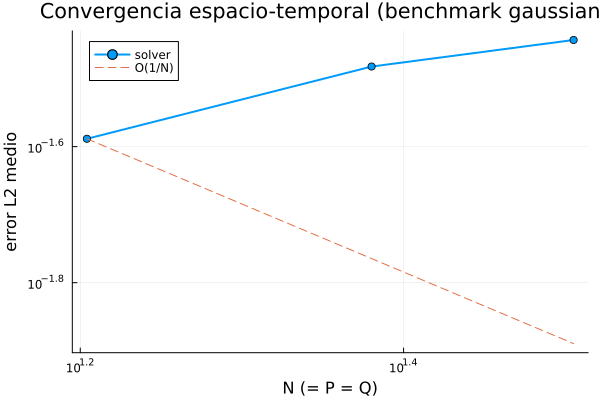

In [30]:
# Error L2 vs N en log-log, con pendiente de referencia O(1/N).
figN = plot(collect(Ns), errL2, xscale=:log10, yscale=:log10, marker=:circle, lw=2,
            label="solver", xlabel="N (= P = Q)", ylabel="error L2 medio",
            title="Convergencia espacio-temporal (benchmark gaussiano)")
plot!(figN, collect(Ns), errL2[1] .* (Ns[1] ./ collect(Ns)), ls=:dash, label="O(1/N)")
savefig(figN, "convergencia.png")
figN

## §5 — Costos generalizados $\Phi_\beta$

$\beta=1$ Wasserstein, $\beta=0$ mezcla lineal. El único cambio es el polinomio del paso
proximal, ya en `prox_energia`. Barrido $\beta\in\{0,\tfrac12,1\}$.

In [31]:
betas = (0.0, 0.5, 1.0)
Vbetas = Dict()
for β in betas
    @time Xb, Vb, hb = solve_bb(f0, f1, d; β=β, ε=ε, niter=600, verbose=200)
    Vbetas[β] = Vb
    spb, _ = dispersion(Vb[:,:,d[3]÷2,3])
    @printf("beta=%.2f  dispersion(t=0.5)=%.4f\n", β, spb)
end

    it=   1/600  ||div||=2.34e-03  minρ=9.07e-05
    it=  10/600  ||div||=2.31e-03  minρ=9.07e-05
    it=  20/600  ||div||=8.66e-04  minρ=9.07e-05
    it=  30/600  ||div||=4.69e-03  minρ=9.07e-05
    it=  40/600  ||div||=3.31e-03  minρ=9.07e-05
    it=  50/600  ||div||=6.49e-04  minρ=9.07e-05
    it=  60/600  ||div||=2.66e-03  minρ=9.07e-05
    it=  70/600  ||div||=3.20e-03  minρ=9.07e-05
    it=  80/600  ||div||=9.64e-04  minρ=9.07e-05
    it=  90/600  ||div||=1.39e-03  minρ=9.07e-05
    it= 100/600  ||div||=2.54e-03  minρ=9.07e-05
    it= 110/600  ||div||=1.29e-03  minρ=9.07e-05
    it= 120/600  ||div||=7.40e-04  minρ=9.07e-05
    it= 130/600  ||div||=1.68e-03  minρ=9.07e-05
    it= 140/600  ||div||=1.32e-03  minρ=9.07e-05
    it= 150/600  ||div||=5.20e-04  minρ=9.07e-05
    it= 160/600  ||div||=9.56e-04  minρ=9.07e-05
    it= 170/600  ||div||=1.10e-03  minρ=9.07e-05
    it= 180/600  ||div||=4.70e-04  minρ=9.07e-05
    it= 190/600  ||div||=4.87e-04  minρ=9.07e-05
    it= 200/600  ||d

    it= 410/600  ||div||=3.30e-04  minρ=4.98e-05
    it= 420/600  ||div||=2.43e-04  minρ=5.22e-05
    it= 430/600  ||div||=2.04e-04  minρ=5.50e-05
    it= 440/600  ||div||=2.05e-04  minρ=5.87e-05
    it= 450/600  ||div||=1.82e-04  minρ=6.27e-05
    it= 460/600  ||div||=1.62e-04  minρ=6.66e-05
    it= 470/600  ||div||=1.41e-04  minρ=7.00e-05
    it= 480/600  ||div||=1.38e-04  minρ=7.30e-05
    it= 490/600  ||div||=1.09e-04  minρ=7.69e-05
    it= 500/600  ||div||=1.17e-04  minρ=8.05e-05
    it= 510/600  ||div||=1.23e-04  minρ=8.26e-05
    it= 520/600  ||div||=1.44e-04  minρ=8.33e-05
    it= 530/600  ||div||=9.59e-05  minρ=8.34e-05
    it= 540/600  ||div||=1.01e-04  minρ=8.40e-05
    it= 550/600  ||div||=1.13e-04  minρ=8.41e-05
    it= 560/600  ||div||=7.40e-05  minρ=8.33e-05
    it= 570/600  ||div||=7.75e-05  minρ=8.32e-05
    it= 580/600  ||div||=1.05e-04  minρ=8.35e-05
    it= 590/600  ||div||=1.33e-04  minρ=8.40e-05
    it= 600/600  ||div||=1.65e-04  minρ=8.43e-05
 39.234702 seconds (

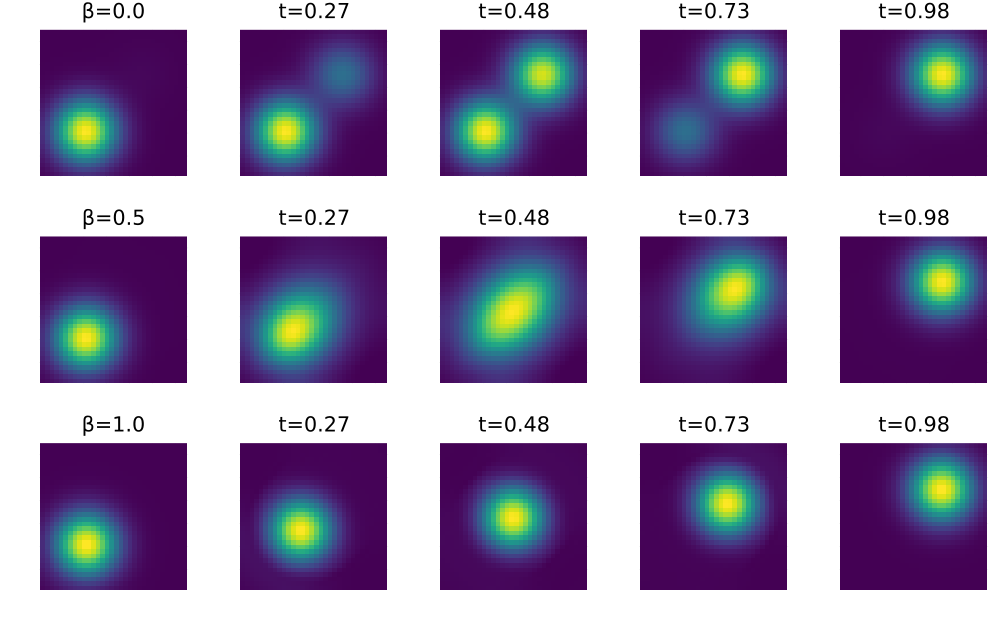

In [32]:
selb = round.(Int, range(1, d[3]; length=5))
cuadros = []
for β in betas, j in selb
    push!(cuadros, heatmap(Vbetas[β][:,:,j,3]', c=:viridis, axis=false, legend=false,
          colorbar=false, aspect_ratio=:equal,
          title=(j==selb[1] ? "β=$β" : "t=$(round((j-0.5)/d[3],digits=2))")))
end
figb = plot(cuadros..., layout=(length(betas), length(selb)), size=(1000,620))
savefig(figb, "barrido_beta.png")
figb

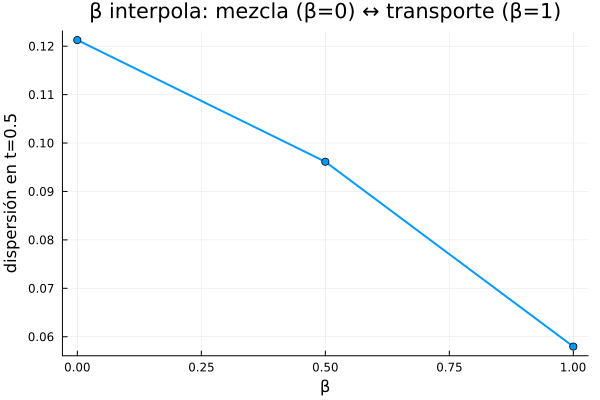

In [33]:
disps = [dispersion(Vbetas[β][:,:,d[3]÷2,3])[1] for β in betas]
figbd = plot(collect(betas), disps, marker=:circle, lw=2, legend=false,
             xlabel="β", ylabel="dispersión en t=0.5",
             title="β interpola: mezcla (β=0) ↔ transporte (β=1)")
savefig(figbd, "dispersion_vs_beta.png")
figbd

### §5.1 — Energía cinética: transporte vs. mezcla

La energía cinética física es $\int|m|^2/(2\rho)$ (el caso $\beta=1$). Evaluándola sobre cada
solución del barrido —todas con la misma vara $\beta=1$— se mide cuánta energía gasta cada
régimen: el transporte óptimo es el de menor energía, y la mezcla lineal la más cara.

beta=0.00  J_cinetica=13.9665
beta=0.50  J_cinetica=4.9627
beta=1.00  J_cinetica=3.8272

Transporte (β=1) gasta 3.6x menos energía que la mezcla (β=0):  3.827  vs  13.966


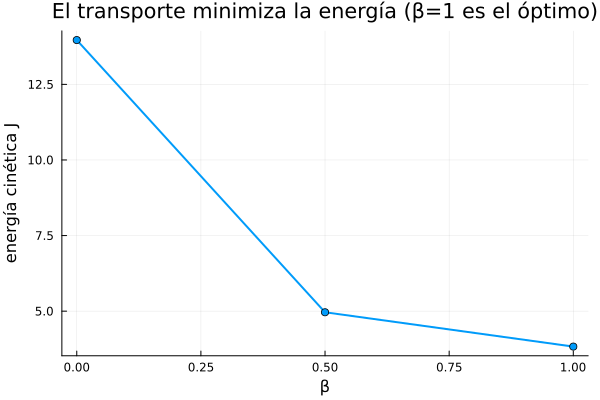

In [34]:
# Energia cinetica (evaluada con beta=1 SIEMPRE, la vara comun) de cada solucion del barrido.
Jbetas = [energia_BB(Vbetas[β]; ε=1e-4, β=1.0) for β in betas]
for (β, J) in zip(betas, Jbetas)
    @printf("beta=%.2f  J_cinetica=%.4f\n", β, J)
end
@printf("\nTransporte (β=1) gasta %.1fx menos energía que la mezcla (β=0):  %.3f  vs  %.3f\n",
        Jbetas[1]/Jbetas[end], Jbetas[end], Jbetas[1])
figJ = plot(collect(betas), Jbetas, lw=2, marker=:circle, legend=false,
            xlabel="β", ylabel="energía cinética J",
            title="El transporte minimiza la energía (β=1 es el óptimo)")
savefig(figJ, "energia_vs_beta.png")
figJ

In [35]:
for epsv in (1e-3, 1e-4, 1e-5, 1e-6)
    Js = [energia_BB(Vbetas[β]; ε=epsv, β=1.0) for β in betas]
    @printf("eps=%.0e : ", epsv)
    for (β,J) in zip(betas,Js); @printf("β=%.2f→%.3f  ", β, J); end
    println()
end

eps=1e-03 : β=0.00→4.769  β=0.50→3.728  β=1.00→3.613  
eps=1e-04 : β=0.00→13.966  β=0.50→4.963  β=1.00→3.827  
eps=1e-05 : β=0.00→14.074  β=0.50→4.974  β=1.00→3.829  
eps=1e-06 : β=0.00→14.074  β=0.50→4.974  β=1.00→3.829  


In [36]:
# Reevaluar la energía con eps fisico, sobre las Vbetas YA computadas (instantáneo)
Jbetas = [energia_BB(Vbetas[β]; ε=1e-5, β=1.0) for β in betas]
for (β, J) in zip(betas, Jbetas)
    @printf("beta=%.2f  J_cinetica=%.4f\n", β, J)
end

beta=0.00  J_cinetica=14.0743
beta=0.50  J_cinetica=4.9737
beta=1.00  J_cinetica=3.8288


### §5.2 — Imágenes de prueba sintéticas (utilidades)

Densidades de prueba a partir de formas: redimensión por promedio de área,
`forma_disco`/`forma_cuadrado`, y `a_densidad` (masa 1, inversión opcional, piso de fondo
por fracción, margen para el no-flujo). La carga de PNG reales (`cargar_gris`, requiere
PNGFiles) vive en el notebook de morphing de fotos.

In [37]:
# --- Redimensión por promedio de área (separable) ---
# Matriz de remuestreo 1D por solapamiento de intervalos: nin -> nout. Cada fila suma 1 (promedio).
function remuestreo_1d(nin, nout)
    W = zeros(nout, nin)
    for o in 1:nout
        a = (o-1)/nout; b = o/nout                # intervalo de salida [a,b]
        for i in 1:nin
            c = (i-1)/nin; d = i/nin              # intervalo de entrada [c,d]
            W[o,i] = max(0.0, min(b,d) - max(a,c)) # longitud de solapamiento
        end
        W[o,:] ./= sum(W[o,:])                     # normaliza a promedio
    end
    return W
end

# Redimensiona una matriz (H,Wd) -> (N,P) por promedio de área.
function redimensionar(A, dim2d)
    N, P = dim2d
    H, Wd = size(A)
    return remuestreo_1d(H, N) * A * remuestreo_1d(Wd, P)'
end

# --- Formas sintéticas de prueba (intensidad en [0,1], 1 = tinta) ---
function forma_disco(dim2d, centro, r)
    N, P = dim2d; cx, cy = centro
    x = range(0,1;length=N); y = range(0,1;length=P)
    return Float64[ (xi-cx)^2 + (yj-cy)^2 <= r^2 ? 1.0 : 0.0 for xi in x, yj in y]
end

function forma_cuadrado(dim2d, centro, lado)
    N, P = dim2d; cx, cy = centro
    x = range(0,1;length=N); y = range(0,1;length=P)
    return Float64[ (abs(xi-cx) <= lado/2 && abs(yj-cy) <= lado/2) ? 1.0 : 0.0 for xi in x, yj in y]
end

# --- Conversión intensidad -> densidad válida (masa 1, rho>0) ---
#   invertir    : true  => tinta oscura (valores bajos) pasa a masa alta (PNG típico, fondo blanco)
#                 false => los valores altos ya son masa (formas sintéticas con tinta=1)
#   frac_fondo  : fracción de la masa total asignada al fondo (controla contraste y rho>0)
#   margen      : nº de celdas de borde forzadas a fondo (deja la masa lejos de la frontera)
function a_densidad(raw, dim2d; invertir=true, frac_fondo=0.02, margen=1)
    N, P = dim2d
    f = redimensionar(Float64.(raw), dim2d)
    f .-= minimum(f); mx = maximum(f); mx > 0 && (f ./= mx)   # intensidad a [0,1]
    invertir && (f .= 1 .- f)                                 # tinta -> masa
    if margen > 0                                             # margen de fondo
        f[1:margen,:] .= 0; f[end-margen+1:end,:] .= 0
        f[:,1:margen] .= 0; f[:,end-margen+1:end] .= 0
    end
    s = sum(f)                                                # piso por fracción de masa de fondo:
    c = frac_fondo*s / (N*P*(1-frac_fondo))                   #   frac ≈ c*N*P/(s + c*N*P)
    f .+= c
    f ./= sum(f)                                              # masa 1
    return f
end
println("Datos (síntesis + conversión) listos.")

Datos (síntesis + conversión) listos.


masa f0=1.000000000000  f1=1.000000000000   min f0=4.88e-06  f1=4.88e-06


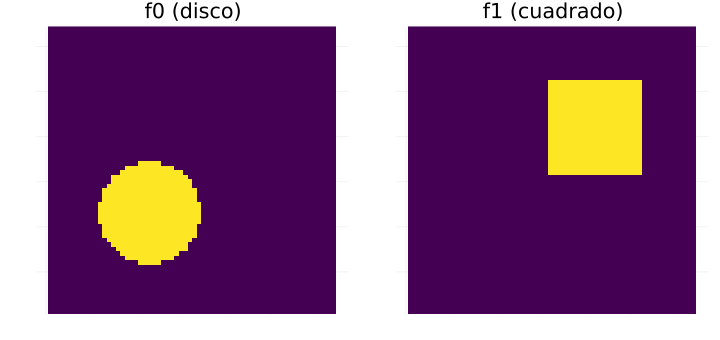

In [38]:
# TEST §6.1 (síntesis, sin solver): masa 1, positividad, y vista para confirmar orientación.
let
    N, P = 64, 64
    f0 = a_densidad(forma_disco((N,P),(0.35,0.35),0.18), (N,P); invertir=false, frac_fondo=0.02, margen=1)
    f1 = a_densidad(forma_cuadrado((N,P),(0.65,0.65),0.34), (N,P); invertir=false, frac_fondo=0.02, margen=1)
    @assert abs(sum(f0)-1) < 1e-12 && abs(sum(f1)-1) < 1e-12
    @assert minimum(f0) > 0 && minimum(f1) > 0
    @printf("masa f0=%.12f  f1=%.12f   min f0=%.2e  f1=%.2e\n", sum(f0), sum(f1), minimum(f0), minimum(f1))
    plot(heatmap(f0', c=:viridis, aspect_ratio=:equal, axis=false, colorbar=false, title="f0 (disco)"),
         heatmap(f1', c=:viridis, aspect_ratio=:equal, axis=false, colorbar=false, title="f1 (cuadrado)"),
         layout=(1,2), size=(720,340))
end

### §5.3 — Barrido de $\beta$ sobre imágenes de prueba (Objetivo 5.iii)

Las mismas formas resueltas con $\beta\in\{0,\tfrac12,1\}$: $\beta=0$ ($H^{-1}$) hace
aparecer/desvanecer la masa, $\beta=1$ (Wasserstein) la transporta, $\beta=\tfrac12$
interpola. Se cuantifica con la dispersión en $t=0.5$ y la energía de transporte
(vara común $\beta=1$).

In [39]:
dβ  = (64, 64, 20)
f0β = a_densidad(forma_disco((dβ[1],dβ[2]),(0.35,0.35),0.18), (dβ[1],dβ[2]); invertir=false)
f1β = a_densidad(forma_cuadrado((dβ[1],dβ[2]),(0.65,0.65),0.34), (dβ[1],dβ[2]); invertir=false)
εβ  = min(minimum(f0β), minimum(f1β))

betas_img = (0.0, 0.5, 1.0)
Vβ = Dict()
for β in betas_img
    _, Vb, _ = solve_bb(f0β, f1β, dβ; β=β, ε=εβ, γ=1/230, niter=600, verbose=200)
    Vβ[β] = Vb
    sp, _ = dispersion(Vb[:,:,dβ[3]÷2,3])
    EB = energia_BB(Vb; ε=εβ, β=1.0)                      # energía de transporte (vara común β=1)
    @printf("β=%.2f  dispersión(t=0.5)=%.4f  energía_transporte=%.4f\n", β, sp, EB)
end

    it=   1/600  ||div||=8.21e-04  minρ=4.88e-06
    it=  10/600  ||div||=1.31e-03  minρ=4.88e-06
    it=  20/600  ||div||=5.50e-04  minρ=4.88e-06
    it=  30/600  ||div||=1.98e-03  minρ=4.88e-06
    it=  40/600  ||div||=1.75e-03  minρ=4.88e-06
    it=  50/600  ||div||=7.27e-04  minρ=4.88e-06
    it=  60/600  ||div||=1.26e-03  minρ=4.88e-06
    it=  70/600  ||div||=1.77e-03  minρ=4.88e-06
    it=  80/600  ||div||=8.35e-04  minρ=4.88e-06
    it=  90/600  ||div||=7.65e-04  minρ=4.88e-06
    it= 100/600  ||div||=1.28e-03  minρ=4.88e-06
    it= 110/600  ||div||=9.54e-04  minρ=4.88e-06
    it= 120/600  ||div||=6.68e-04  minρ=4.88e-06
    it= 130/600  ||div||=9.72e-04  minρ=4.88e-06
    it= 140/600  ||div||=8.96e-04  minρ=4.88e-06
    it= 150/600  ||div||=5.05e-04  minρ=4.88e-06
    it= 160/600  ||div||=6.27e-04  minρ=4.88e-06
    it= 170/600  ||div||=7.19e-04  minρ=4.88e-06
    it= 180/600  ||div||=6.36e-04  minρ=4.88e-06
    it= 190/600  ||div||=5.22e-04  minρ=4.88e-06
    it= 200/600  ||d

    it= 420/600  ||div||=3.61e-04  minρ=-1.13e-05
    it= 430/600  ||div||=4.60e-04  minρ=-1.20e-05
    it= 440/600  ||div||=4.14e-04  minρ=-1.04e-05
    it= 450/600  ||div||=3.74e-04  minρ=-1.04e-05
    it= 460/600  ||div||=3.08e-04  minρ=-7.30e-06
    it= 470/600  ||div||=2.78e-04  minρ=-8.07e-06
    it= 480/600  ||div||=2.19e-04  minρ=-8.12e-06
    it= 490/600  ||div||=1.73e-04  minρ=-6.93e-06
    it= 500/600  ||div||=1.95e-04  minρ=-9.74e-06
    it= 510/600  ||div||=2.32e-04  minρ=-8.91e-06
    it= 520/600  ||div||=2.13e-04  minρ=-8.62e-06
    it= 530/600  ||div||=2.15e-04  minρ=-1.01e-05
    it= 540/600  ||div||=1.99e-04  minρ=-5.86e-06
    it= 550/600  ||div||=2.16e-04  minρ=-5.73e-06
    it= 560/600  ||div||=1.88e-04  minρ=-3.09e-06
    it= 570/600  ||div||=1.38e-04  minρ=-2.45e-06
    it= 580/600  ||div||=1.75e-04  minρ=-2.13e-06
    it= 590/600  ||div||=1.50e-04  minρ=-2.63e-06
    it= 600/600  ||div||=1.74e-04  minρ=-2.52e-06
β=1.00  dispersión(t=0.5)=0.0211  energía_transpor

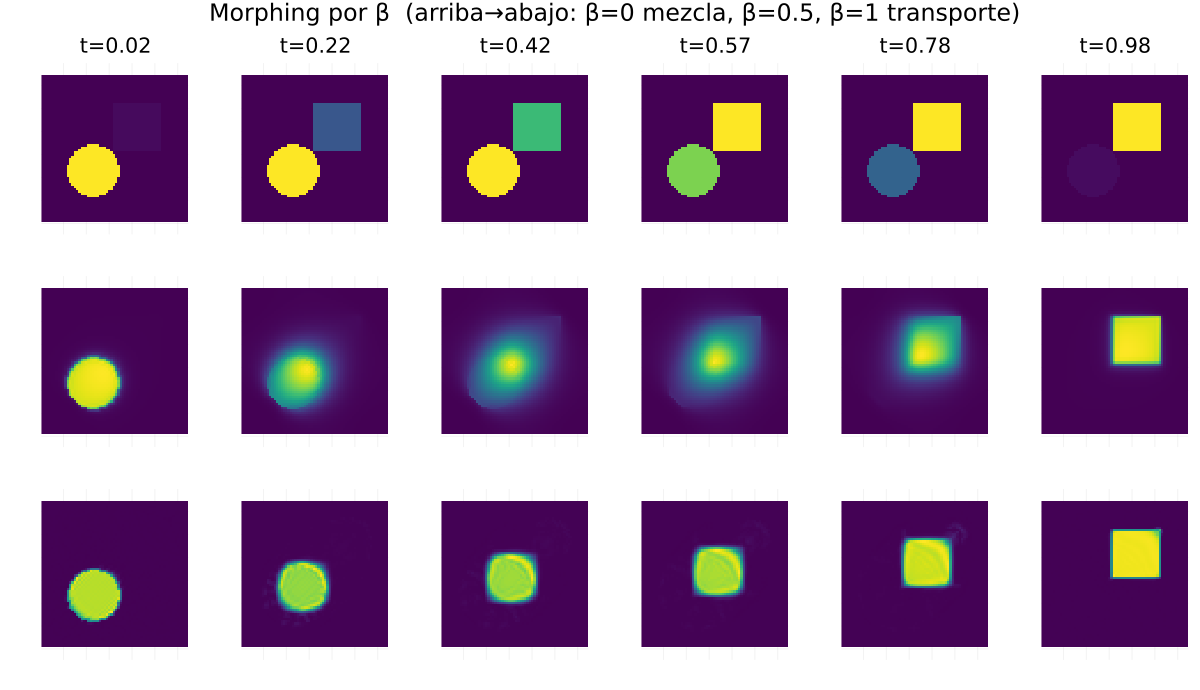

In [40]:
# Secuencias lado a lado: filas = β (0, 0.5, 1), columnas = t.
selβ = round.(Int, range(1, dβ[3]; length=6))
filas = Any[]
for β in betas_img
    for j in selβ
        titulo = β == betas_img[1] ? "t=$(round((j-0.5)/dβ[3],digits=2))" : ""
        push!(filas, heatmap(Vβ[β][:,:,j,3]', c=:viridis, axis=false, legend=false,
              colorbar=false, aspect_ratio=:equal, title=titulo))
    end
end
figβ = plot(filas..., layout=(length(betas_img), length(selβ)),
            size=(1200, 230*length(betas_img)),
            plot_title="Morphing por β  (arriba→abajo: β=0 mezcla, β=0.5, β=1 transporte)")
savefig(figβ, "morphing_betas.png")
figβ

---
### Referencias
Benamou & Brenier (2000); Papadakis, Peyré & Oudet (2014); Santambrogio (2015);
Dolbeault, Nazaret & Savaré (2009).